In [15]:
import numpy as np
import pynbody as pnb
import os
import h5py
from pynbody.analysis.profile import Profile, VerticalProfile, InclinedProfile, QuantileProfile
import argparse
import dill
import caesar
import yt
import astropy.constants as astroc

m_p = astroc.m_p.cgs.value # mass of proton in cgs units
k_B = astroc.k_B.cgs.value # Boltzmann constant in cgs units
from astro_constants import NA_no_units, NA, kB_no_units, kB, mH, mp_no_units, mu_e, mu, G_no_units, G

profile_types = {
    'Profile':Profile,
    'VerticalProfile':VerticalProfile,
    'InclinedProfile':InclinedProfile,
    'QuantileProfile':QuantileProfile,
}

code = 'Simba-C'
name = 'entropy_prof_L1_zoom_252_644' # for output file name
#snap_file = args.snap
#output_file = args.output_filepath + '_temp_cut='+args.temp_cut+'_nh_cut='+args.nh_cut+'.pkl'
output_filename = name + '_temp_cut=5e5K_nh_cut=0.13_cm-3.pkl'
profile_type = profile_types['Profile']
weight_by = 'mass'

# define args
snap_file = '/scratch/b/babul/aspadawe/snapshots/Hyenasc_L0_zooms/halo_3224/snap_halo_3224_151.hdf5'
output_path = '/home/b/babul/stlock/entropy_profiles/outputs/'
temp_cut = '5e5 K' # default for now
nh_cut = '0.13 cm**-3' # default for now

print()
print('Reading in simulation snapshot')
s = pnb.load(snap_file)
s.physical_units()
s.gas['pos']/=1000 # convert to kpc
print(s.gas['pos'].units)
print(s.gas['pos'][0])
print(s.gas['pos'][1].in_units('kpc'))
print(s.properties)
print('done')
print()


Reading in simulation snapshot
kpc
[143900.48 142922.92 143582.6 ]
[143900.88 142922.27 143581.72]
{'a': 0.9999999999999996, 'omegaM0': 0.3, 'omegaL0': 0.7, 'boxsize': Unit("2.94e+08 kpc"), 'h': 0.68, 'time': Unit("1.42e+01 kpc s km**-1"), 'Flag_Cooling': 1, 'Flag_DoublePrecision': 0, 'Flag_Feedback': 1, 'Flag_IC_Info': 3, 'Flag_Metals': 11, 'Flag_Sfr': 1, 'Flag_StellarAge': 1, 'MassTable': array([0., 0., 0., 0., 0., 0.]), 'NumFilesPerSnapshot': 1, 'NumPart_ThisFile': array([2243885, 2515456, 2581553,       0,  162809,     617], dtype=uint32), 'NumPart_Total': array([2243885, 2515456, 2581553,       0,  162809,     617], dtype=uint32), 'NumPart_Total_HighWord': array([0, 0, 0, 0, 0, 0], dtype=uint32), 'Redshift': 4.440892098500626e-16}
done



In [2]:
print(s.gas['pos'].units)
print(s.gas['pos'][0])
print(s.gas['pos'][0].in_units('kpc'))
print('units: ',s.gas['pos'][0])
print(s.gas.properties)
print(s.gas['mass'][:10])
print(s.gas['mass'].units)
print(s.gas['u'][:10])

# correct conversion!
"""s['pos'].units = 'pc'
s.gas['pos'][0].in_units('kpc')
print(s.gas['pos'][:10])"""

kpc
[143900.48 142922.92 143582.6 ]
[143900.48 142922.92 143582.6 ]
units:  [143900.48 142922.92 143582.6 ]
{'a': 0.9999999999999996, 'omegaM0': 0.3, 'omegaL0': 0.7, 'boxsize': Unit("2.94e+08 kpc"), 'h': 0.68, 'time': Unit("1.42e+01 kpc s km**-1"), 'Flag_Cooling': 1, 'Flag_DoublePrecision': 0, 'Flag_Feedback': 1, 'Flag_IC_Info': 3, 'Flag_Metals': 11, 'Flag_Sfr': 1, 'Flag_StellarAge': 1, 'MassTable': array([0., 0., 0., 0., 0., 0.]), 'NumFilesPerSnapshot': 1, 'NumPart_ThisFile': array([2243885, 2515456, 2581553,       0,  162809,     617], dtype=uint32), 'NumPart_Total': array([2243885, 2515456, 2581553,       0,  162809,     617], dtype=uint32), 'NumPart_Total_HighWord': array([0, 0, 0, 0, 0, 0], dtype=uint32), 'Redshift': 4.440892098500626e-16}
[21749352. 20361472. 24304748. 20335280. 21988556. 20968872. 19337350.
 20069730. 18814158. 19684278.]
Msol
[503.05966 455.225   568.16113 477.50766 432.98703 403.62662 463.58362
 444.55835 409.96786 476.73553]


"s['pos'].units = 'pc'\ns.gas['pos'][0].in_units('kpc')\nprint(s.gas['pos'][:10])"

In [3]:
#useful functions, XIGrM, dill, etc

r_units = 'kpc'

def save_object_with_dill(obj, filename):
    with open(filename, 'wb') as f:  # Overwrites any existing file.
        dill.dump(obj, f, dill.HIGHEST_PROTOCOL)

# XIGrM Functions
def nh(sim):
    '''
    Calculating hydrogen number density from density.
    '''
    #X_H = 1-sim.gas['metals'][:,0]-sim.gas['metals'][:,1] #0 for metal and 1 for He
    result = sim.gas['rho'].in_units('g cm**-3').view(np.ndarray)/m_p*sim.gas['X_H']
    result = pnb.array.SimArray(result)
    result.units = 'cm**-3'
    return result


def temp(sim):
    '''
    Convert internal energy to temperature, following 
    the instructions from `GIZMO documentation <http://www.tapir.caltech.edu/~phopkins/Site/GIZMO_files/gizmo_documentation.html#snaps>`_
    '''
    #XH = 1-sim.gas['metals'][:,0]-sim.gas['metals'][:,1]
    GAMMA = 5.0/3
    # If ne = 0 gas is unionized
    mu = 4.0 / (3.0 * sim.gas['X_H'] + 4.0 * sim.gas['X_H'] * sim.gas['ElectronAbundance'] + 1.0)
    # mu = 0.6
    result = pnb.array.SimArray(sim.gas['u'].in_units('cm**2 s**-2').view(np.ndarray) * (GAMMA - 1) * mu * (m_p / k_B))
    result.units = 'K'
    return result

@Profile.profile_property
def Ne(self):
    with self.sim.immediate_mode:
        pvol_ = self.sim['volume'].in_units('cm**3')
        pvol = pvol_.view(np.ndarray)
        pne_ = self.sim['ne'].in_units('cm**-3')
        pne = pne_.view(np.ndarray)
    
    Ne_ = pnb.array.SimArray(np.zeros(self.nbins), units=pvol_.units * pne_.units)
    for i in range(self.nbins):
        if len(self.binind[i]) == 0:
            Ne_[i] = 0
        else:
            Ne_[i] = np.nansum(pvol[self.binind[i]] * pne[self.binind[i]], axis=0)#.sum()
    return Ne_


@Profile.profile_property
def volume(self):
    return self._binsize

@Profile.profile_property # call as something like result['y'][prop + '_' + weight] = prop_weighted_avg(pg, prop, weight)
def prop_weighted_avg(self, prop, weight):
    with self.sim.immediate_mode:
        pprop_ = self.sim[prop]
        pprop = pprop_.view(np.ndarray)
        pweight_ = self.sim[weight]
        pweight = pweight_.view(np.ndarray)

    result = pnb.array.SimArray(np.zeros((self.nbins,) + pprop.shape[1:]), units=pprop_.units)
    for i in range(self.nbins):
        if len(self.binind[i]) == 0:
            result[i] = np.nan
        else:
            result[i] = np.average(pprop[self.binind[i]], weights=pweight[self.binind[i]], axis=0)
    return result



def remove_outliers(particle):
    particle = np.array(particle)
    
    # Compute Q1 (25th percentile) and Q3 (75th percentile) for each axis
    Q1 = np.percentile(particle, 25, axis=0)
    Q3 = np.percentile(particle, 75, axis=0)
    
    # Compute IQR (Interquartile Range)
    IQR = Q3 - Q1
    
    # Define lower and upper bounds for non-outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Mask to filter out outliers
    mask = np.all((particle >= lower_bound) & (particle <= upper_bound), axis=1)
    
    return particle[mask]



In [4]:
# caesar halo finding
# we are getting the halo ID from the snapshots, so we need to use that to ID the halo!
obj = caesar.load('/scratch/b/babul/aspadawe/snapshots/Hyenasc_L0_zooms/halo_3224/Groups/Caesar_halo_3224_151.hdf5')
halo_data = obj.halos

gas_positions = s.gas['pos'] #gas positions in kpc

#gas_positions = remove_outliers(gas_positions)

# Find min and max x, y, z of all gas particles. half them to make a rough centerpoint
min_x, min_y, min_z = np.min(gas_positions, axis=0)
max_x, max_y, max_z = np.max(gas_positions, axis=0)


half_x, half_y, half_z = (min_x+max_x)/2, (min_y+max_y)/2, (min_z+max_z)/2


length_x, length_y, length_z = np.abs(max_x-min_x)/2, np.abs(max_y-min_y)/2, np.abs(max_z-min_z)/2

# Find all halos that have a centerpoint within 1Mpc from the rough centerpoint

center_arr = np.array([halo.minpotpos.in_units('kpc') for halo in halo_data]) # array of all halo centers from halo_data
m500c_arr = np.array([halo.virial_quantities['m500c'] for halo in halo_data]) # array of all halo masses from halo_data
r500c_arr = np.array([halo.virial_quantities['r500c'] for halo in halo_data]) # array of all halo radii from halo_data
center_arr_x = center_arr[:, 0]  # Get all rows, first column (x-coordinates)
center_arr_y = center_arr[:, 1]  # second column (y-coords)
center_arr_z = center_arr[:, 2]  # third column (z-coords)

rad_array = ((center_arr_x - half_x)**2 + (center_arr_y - half_y)**2 + (center_arr_z - half_z)**2 )**(0.5)
radial_cut_ids = np.where(rad_array <= max(length_x, length_y, length_z)) # within length of longest side of box from center


candidate_indices = radial_cut_ids[0]  # np.where returns a tuple; use the first element

# Select the corresponding m500c values (halo masses)
candidate_masses = m500c_arr[candidate_indices]

# Find the index (in candidate_indices) of the halo with maximum mass
largest_candidate_index = candidate_indices[np.argmax(candidate_masses)]
center = center_arr[largest_candidate_index]  # in kpc (already converted)
r500 = r500c_arr[largest_candidate_index]       # likely in kpccm

print("Largest Halo Center (kpc):", center)
print("Largest Halo r500 (kpc):", r500)


yt : [INFO     ] 2025-03-11 21:59:02,879 Opening /scratch/b/babul/aspadawe/snapshots/Hyenasc_L0_zooms/halo_3224/Groups/Caesar_halo_3224_151.hdf5
yt : [INFO     ] 2025-03-11 21:59:02,911 Found 1021 halos
yt : [INFO     ] 2025-03-11 21:59:02,916 Found 320 galaxies


Largest Halo Center (kpc): [154536.5  132680.1  156805.19]
Largest Halo r500 (kpc): 366.17291259765625


In [5]:
## Metal indices
if code.lower() == 'simba':
    # Simba
    metals_idx = {'Z':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    metals_idx_xigrm = {'H':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    elems = ['H', 'He', 'C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ca', 'Fe']
elif code.lower() == 'simba-c':
    # Simba-C
    metals_idx = {'Z':0, 'H':1, 'He': 2, 'Li': 3, 'Be': 4, 'B': 5, 'C': 6, 'N': 7, 'O': 8, 'F': 9, 'Ne': 10, 'Na': 11, 'Mg': 12, 'Al':13,
                  'Si': 14, 'P': 15, 'S': 16, 'Cl': 17, 'Ar': 18, 'K': 19,'Ca': 20, 'Sc': 21, 'Ti': 22, 'V': 23, 'Cr': 24,
                  'Mn': 25, 'Fe': 26, 'Co': 27, 'Ni': 28, 'Cu': 29, 'Zn': 30}
    metals_idx_xigrm = {'H':0, 'He': 1, 'Li': 2, 'Be': 3, 'B': 4, 'C': 5, 'N': 6, 'O': 7, 'F': 8, 'Ne': 9, 'Na': 10, 'Mg': 11, 
                        'Al':12, 'Si': 13, 'P': 14, 'S': 15, 'Cl': 16, 'Ar': 17, 'K': 18,'Ca': 19, 'Sc': 20, 'Ti': 21, 'V': 22, 'Cr': 23,
                      'Mn': 24, 'Fe': 25, 'Co': 26, 'Ni': 27, 'Cu': 28, 'Zn': 29}
    elems=['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si',
           'P', 'S', 'Cl', 'Ar', 'K','Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn']#, 'Ga', 'Ge']\n",
else:
    raise SystemExit('Code is not Simba or Simba-C')

s.gas['u'] /= pnb.array.SimArray(s.properties['a'], units='1')

# Hydrogen mass fraction

if code.lower() == 'simba': # might as well keep the simba stuff
    s.gas['X_H'] = 1-s.gas['metals'][:,metals_idx['Z']]-s.gas['metals'][:,metals_idx['He']]
elif code.lower() == 'simba-c':
    s.gas['X_H'] = s.gas['metals'][:,metals_idx['H']]
    
s.gas['X_H'] = s.gas['metals'][:,metals_idx['H']]

s.gas['nh'] = nh(s) # Hydrogen number density
s.gas['ElectronAbundance'].units = '1'

print(f"Sample temp(s) output: {temp(s)[:5]}")
print(f"Any NaNs in temp(s)? {np.any(np.isnan(temp(s)))}")


s.gas['T'] = temp(s) # From internal energy to temperature
s.gas['temp'] = s.gas['T']
# s.gas['ne'] = s.gas['ElectronAbundance'] * s.gas['nh'].in_units('cm**-3') # ???

print(f"Total gas particles: {len(s.gas)}")

## Get hot diffuse gas using provided cuts
print('Isolating IGrM (temperate, hydrogen number density, and decoupled wind particle cuts)')
temp_cut = '5e5 K' # default for now
nh_cut = '0.13 cm**-3' # default for now
temp_filt = pnb.filt.HighPass('T', temp_cut)
density_filt = pnb.filt.LowPass('nh', nh_cut)
wind_filt = ~pnb.filt.HighPass('DelayTime', 0)  # Cut out hot decoupled wind particles
total_filt = temp_filt & density_filt & wind_filt

print('sample gas position before filter: ', s.gas['pos'][0])
hotdiffusegas = s.gas[total_filt]
print(f"Particles after filtering: {len(hotdiffusegas)}")
print('sample gas position after filter: ', hotdiffusegas['pos'][0])

if 'T' in s.gas.loadable_keys():
    hotdiffusegas['T'] = s.gas['T'][total_filt]
    hotdiffusegas['temp'] = hotdiffusegas['T']
    print("Reassigned 'T' and 'temp' to hotdiffusegas.")
else:
    print("Error: 'T' is missing in s.gas.")


# calc entropy
hotdiffusegas['ne'] = hotdiffusegas['ElectronAbundance'] * hotdiffusegas['nh'].in_units('cm**-3') # eletron number density
hotdiffusegas['K'] = kB * hotdiffusegas['T'] * hotdiffusegas['ne']**(-2,3) # entropy  

print(f"hotdiffusegas['pos'] sample: {hotdiffusegas['pos'][:5]}")
print(f"hotdiffusegas['pos'] units: {hotdiffusegas['pos'].units}")
print(f"Center: {center}, units: {pnb.array.SimArray(center).units}")



Sample temp(s) output: [54300.64  51520.836 56955.414 54295.984 46869.824]
Any NaNs in temp(s)? False
Total gas particles: 2243885
Isolating IGrM (temperate, hydrogen number density, and decoupled wind particle cuts)
sample gas position before filter:  [143900.48 142922.92 143582.6 ]
Particles after filtering: 1605467
sample gas position after filter:  [151812.8  146588.36 134427.7 ]
Error: 'T' is missing in s.gas.
hotdiffusegas['pos'] sample: [[151812.8  146588.36 134427.7 ]
 [151820.   146494.06 134507.86]
 [151930.39 146623.16 134690.67]
 [151780.39 146707.12 134554.28]
 [151709.69 146706.5  134570.19]]
hotdiffusegas['pos'] units: kpc
Center: [154536.5  132680.1  156805.19], units: NoUnit()


In [6]:
print(f"Original gas position sample: {s.gas['pos'][0]} {s.gas['pos'].units}")
hotdiffusegas = s.gas[total_filt]  # Apply filtering
print(f"Filtered gas position sample: {hotdiffusegas['pos'][0]} {hotdiffusegas['pos'].units}")


Original gas position sample: [143900.48 142922.92 143582.6 ] kpc
Filtered gas position sample: [151812.8  146588.36 134427.7 ] kpc


In [7]:
print(f"Available fields in s.gas: {s.gas.loadable_keys()}")
print(f"X_H exists: {'X_H' in s.gas.loadable_keys()}")
print(f"Sample X_H values: {s.gas['X_H'][:5] if 'X_H' in s.gas.loadable_keys() else 'MISSING'}")


Available fields in s.gas: ['Dust_Metallicity', 'GrackleHII', 'Sigma', 'FractionH2', 'GrackleHM', 'GrackleHeII', 'AccKey', 'u', 'NeutralHydrogenAbundance', 'GrackleHeIII', 'pos', 'phi', 'GrackleHI', 'Dust_Masses', 'rho', 'ElectronAbundance', 'mass', 'HaloID', 'ID_Generations', 'iord', 'DelayTime', 'metals', 'vel', 'NWindLaunches', 'StarFormationRate', 'smooth', 'GrackleHeI']
X_H exists: False
Sample X_H values: MISSING


In [8]:
def gas_profile(snapshot, center, rbins, profile_type=Profile, profile_ndims=3, weight_by='mass'):
    tx = pnb.transformation.inverse_translate(snapshot, center)
    boxsize = snapshot.properties['boxsize']
    
    log_rbins = np.log10(rbins)
    bin_centres = (rbins[:-1] + rbins[1:])/2.
    log_bin_centres = (log_rbins[:-1] + log_rbins[1:])/2.

    result = {
        'x':{},
        'y':{},
    }
    with tx:
        original_pos = snapshot['pos'].copy()
        
        # Correct the position of particles crossing the box periodical boundary.
#         h_a.correct_pos(snapshot['pos'], boxsize)
        for i in range(3): # Correct the position of particles crossing the box periodical boundary.
            index1, = np.where(snapshot['pos'][:, i] < -boxsize/2)
            snapshot['pos'][index1, i] += boxsize
            index2, = np.where(snapshot['pos'][:, i] > boxsize/2)
            snapshot['pos'][index2, i] -= boxsize


        ## By default, for ndim=2, particles are projected onto x-y axis (ie. with z-axis),
        ## so disc filter is fine
        pg = profile_type(snapshot, ndim=profile_ndims, bins=rbins, weight_by=weight_by)
        
        
        
        ## x-axis values (normalized radius)
        
        result['x']['rbins'] = rbins
        result['x']['log_rbins'] = log_rbins
        result['x']['bin_centres'] = bin_centres
        result['x']['log_bin_centres'] = log_bin_centres

        
        ## y-axis values (entropy)
        
        result['y']['n'] = pnb.array.SimArray(pg['n'], units='') # KEEP, this is the number of particles, we need this
        # result['y']['volume'] = pg['volume']
        if 'Ne' in pg.keys():
            result['y']['Ne'] = pg['Ne']
        else:
            print("Skipping 'Ne' as it is missing from profile.")

        #result['y']['Ne'] = pg['Ne']
        result['y']['mass'] = pg['mass']
        
        result['y']['T_mass'] = prop_weighted_avg(pg, 'temp', 'mass')
        result['y']['K_mass'] = prop_weighted_avg(pg, 'K', 'mass')

                    
        snapshot['pos'] = original_pos

        print(f"Raw T_mass values (first 5): {pg['temp'][:5]}")
        print(f"Raw Ne values (first 5): {pg['Ne'][:5]}")
        print(f"Any NaNs in temp? {np.any(np.isnan(pg['temp']))}")
        print(f"Any NaNs in Ne? {np.any(np.isnan(pg['Ne']))}")
        print(f"Any zeros in Ne? {np.any(pg['Ne'] == 0)}")

    
    return result


In [9]:
# radial binning, 40 bins

rbins = np.append([0], np.logspace(-2, np.log10(10), 40))
xaxis_units_dict = {'R500':''}
r_units = 'kpc'
print(rbins)

rbins = pnb.array.SimArray(rbins, units='kpc')
r500 = pnb.array.SimArray(r500, units='kpc') 
r500 = r500.in_units(r_units) 
print(r500)
print(f"Type of r500: {type(r500)}, Units: {getattr(r500, 'units', 'No units')}")
print(f"Type of rbins: {type(rbins)}, Units: {getattr(rbins, 'units', 'No units')}")

[ 0.          0.01        0.01193777  0.01425103  0.01701254  0.02030918
  0.02424462  0.02894266  0.03455107  0.04124626  0.04923883  0.05878016
  0.07017038  0.08376776  0.1         0.11937766  0.14251027  0.17012543
  0.20309176  0.2424462   0.28942661  0.34551073  0.41246264  0.49238826
  0.58780161  0.70170383  0.83767764  1.          1.19377664  1.42510267
  1.70125428  2.03091762  2.42446202  2.89426612  3.45510729  4.12462638
  4.92388263  5.87801607  7.01703829  8.3767764  10.        ]
366.17291259765625
Type of r500: <class 'pynbody.array.SimArray'>, Units: kpc
Type of rbins: <class 'pynbody.array.SimArray'>, Units: kpc


In [10]:
# radial binning, 40 bins
"""
rbins = np.append([0], np.logspace(-2, np.log10(10), 40))
xaxis_units_dict = {'R500':''}
r_units = 'kpc'

rbins = pnb.array.SimArray(rbins, units=xaxis_units_dict['R500'])
r500 = pnb.array.SimArray(r500, units='kpc') 
r500 = r500.in_units(r_units) 
# r500 = pnb.array.SimArray(r500.to(r_units), units=r_units)
"""
## For binning
temp_rbins = rbins * r500
temp_radius = pnb.array.SimArray(temp_rbins[-1], units=r_units)

print(f"Particles before sphere filter: {len(hotdiffusegas)}")
filter_all = pnb.filt.Sphere(radius=3.0*r500, cen=center)
temp_gas = hotdiffusegas[filter_all] #throw this into the gas_profile function then done!
print(f"Particles after sphere filter: {len(temp_gas)}")

# Debugging output
print(f"rho exists: {'rho' in hotdiffusegas.loadable_keys()}")
print(f"mass exists: {'mass' in hotdiffusegas.loadable_keys()}")
print(f"temp exists: {'temp' in hotdiffusegas.loadable_keys()}")
print(f"Sample rho: {hotdiffusegas['rho'][:5]}")
print(f"Sample mass: {hotdiffusegas['mass'][:5]}")
print(f"Sample temp: {hotdiffusegas['temp'][:5]}")

# Ensure volume exists
if 'rho' in hotdiffusegas.loadable_keys() and 'mass' in hotdiffusegas.loadable_keys():
    hotdiffusegas['volume'] = hotdiffusegas['mass'] / hotdiffusegas['rho']
    print("Manually added 'volume' field to hotdiffusegas.")

# Apply spherical filter
filter_all = pnb.filt.Sphere(radius=r500, cen=center)
temp_gas = hotdiffusegas[filter_all]
print(f"Particles after sphere filter: {len(temp_gas)}")

"""
final_prod = gas_profile(temp_gas, center, rbins, profile_type=Profile, profile_ndims=3, weight_by='mass')

# Saving the file

output =  output_path + output_filename
# Save profiles
print()
print('Saving profiles to file')
save_object_with_dill(final_prod, output)
print("saved as "+ output_filename + " in " + output_path)
print('\nDONE\n')'
"""

Particles before sphere filter: 1605467
Particles after sphere filter: 54791
rho exists: True
mass exists: True
temp exists: False
Sample rho: [8.2748505e-07 3.7317398e-07 1.5219797e-08 4.1754568e-08 2.7210382e-08]
Sample mass: [21705360. 18382766. 18651276. 18301020. 20000622.]
Sample temp: [1256300.2   637438.94 1243530.9   940451.75  875947.06]
Manually added 'volume' field to hotdiffusegas.
Particles after sphere filter: 7977


'\nfinal_prod = gas_profile(temp_gas, center, rbins, profile_type=Profile, profile_ndims=3, weight_by=\'mass\')\n\n# Saving the file\n\noutput =  output_path + output_filename\n# Save profiles\nprint()\nprint(\'Saving profiles to file\')\nsave_object_with_dill(final_prod, output)\nprint("saved as "+ output_filename + " in " + output_path)\nprint(\'\nDONE\n\')\'\n'

In [11]:
final_prod = gas_profile(temp_gas, center, temp_rbins, profile_type=Profile, profile_ndims=3, weight_by='mass')

# Saving the file

output =  output_path + output_filename
# Save profiles
print()
print('Saving profiles to file')
save_object_with_dill(final_prod, output)
print("saved as "+ output_filename + " in " + output_path)
print('\nDONE\n')

Skipping 'Ne' as it is missing from profile.
Raw T_mass values (first 5): [988696.78346061             nan             nan             nan
             nan]
Raw Ne values (first 5): [3.25029864e+64 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00]
Any NaNs in temp? True
Any NaNs in Ne? False
Any zeros in Ne? True

Saving profiles to file
saved as entropy_prof_L1_zoom_252_644_temp_cut=5e5K_nh_cut=0.13_cm-3.pkl in /home/b/babul/stlock/entropy_profiles/outputs/

DONE



/tmp/ipykernel_215509/1134903868.py:5: RuntimeWarning: divide by zero encountered in log10
  log_rbins = np.log10(rbins)
/home/b/babul/stlock/.virtualenvs/entropy_venv_12/lib/python3.11/site-packages/pynbody/analysis/profile.py:380: RuntimeWarning: invalid value encountered in scalar divide
  result[i] = (name_array * mass_array).sum() / self['weight_fn'][i]


[1.23853975e+06            nan            nan            nan
            nan            nan 7.09876800e+07            nan
            nan 4.72606432e+08            nan 7.83240832e+08
 8.79827392e+08 1.73955558e+09 2.24947968e+09 1.98816934e+09
 2.51598336e+09 2.39657037e+09 2.90261222e+09 3.12959002e+09
 4.20142541e+09 4.91741338e+09 4.69136333e+09 4.67275418e+09
 3.69337011e+09 3.62246272e+09 3.53258394e+09            nan
            nan            nan            nan            nan
            nan            nan            nan            nan
            nan            nan            nan            nan]


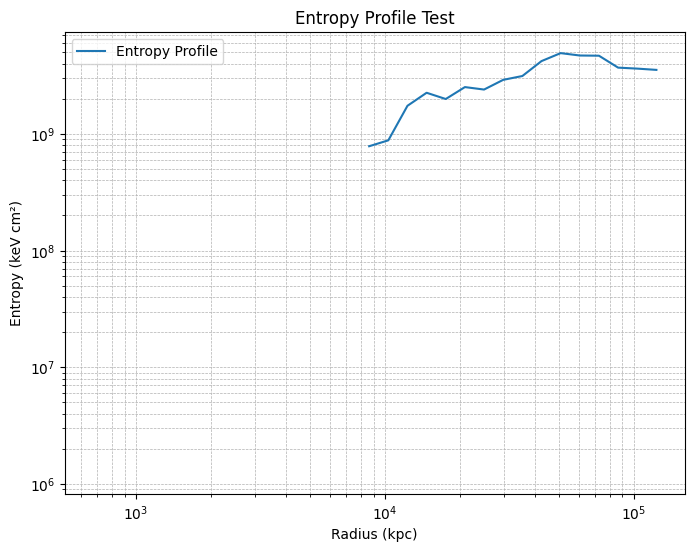

In [12]:
import dill
import matplotlib.pyplot as plt
import numpy as np

# Load the profile from the .pkl file
with open("/home/b/babul/stlock/entropy_profiles/outputs/entropy_prof_L1_zoom_252_644_temp_cut=5e5K_nh_cut=0.13_cm-3.pkl", "rb") as f:
    profile = dill.load(f)

# Extract data
r = r500*profile['x']['bin_centres']  # Radial bin centers
entropy = profile['y']['K_mass']  # Entropy
print(entropy)

# Convert to log scale if necessary
log_r = np.log10(r)
log_entropy = np.log10(entropy)

# Plot
plt.figure(figsize=(8,6))
plt.plot(r, entropy, linestyle='-', label="Entropy Profile")
plt.xscale("log")  # Log scale for radius
plt.yscale("log")  # Log scale for entropy (optional)
plt.xlabel("Radius (kpc)")
plt.ylabel("Entropy (keV cm²)")
plt.title("Entropy Profile Test")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()

In [13]:
print(f"Total hot diffuse gas particles: {len(hotdiffusegas)}")
print(f"Total gas particles: {len(s.gas)}")
print(f"Particles after temp_filt: {len(s.gas[temp_filt])}")
print(f"Particles after density_filt: {len(s.gas[density_filt])}")
print(f"Particles after wind_filt: {len(s.gas[wind_filt])}")
print(f"Particles after all filters (total_filt): {len(hotdiffusegas)}")

print(f"Filter radius: {1.1 * temp_radius}")
print(f"Filter center: {center}")
print(f"temp_radius: {temp_radius}, shape: {temp_radius.shape}")

temp_gas_unfiltered = hotdiffusegas
temp_gas_filtered = hotdiffusegas[filter_all]

print(f"Particles before sphere filter: {len(temp_gas_unfiltered)}")
print(f"Particles after sphere filter: {len(temp_gas_filtered)}")

Total hot diffuse gas particles: 1605467
Total gas particles: 2243885
Particles after temp_filt: 1608804
Particles after density_filt: 2243885
Particles after wind_filt: 2239223
Particles after all filters (total_filt): 1605467
Filter radius: 4027.902038574219
Filter center: [154536.5  132680.1  156805.19]
temp_radius: 3661.7291259765625, shape: ()
Particles before sphere filter: 1605467
Particles after sphere filter: 7977
